# 02 — Quantum Gates & Circuits





## Gates and circuits (Qiskit + Cirq)
We build the same circuits in both frameworks so students see the common ideas.


In [ ]:
!pip install qiskit
!pip install qiskit-aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 83.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=374d3dee4bf4b9ca1db156d6fb56aeb6571496f8f796d3bf3b0b4832e04bc0e3
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


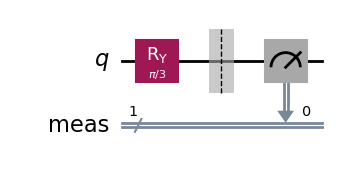

In [ ]:
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.quantum_info import Statevector
# Qiskit: single-qubit rotation + measurement
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

theta = np.pi/3

qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()
qc.draw('mpl')

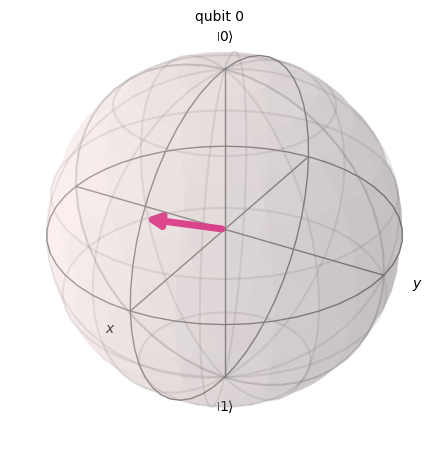

In [ ]:
# qc_clean= qc.remove_final_measurements(inplace=False)
# state = Statevector.from_instruction(qc_clean)
# plot_bloch_multivector(state)

In [ ]:
print(qc)

        ┌─────────┐ ░ ┌─┐
     q: ┤ Ry(π/3) ├─░─┤M├
        └─────────┘ ░ └╥┘
meas: 1/═══════════════╩═
                       0 


In [ ]:
# sim = AerSimulator()
# result= sim.run(qc).result()
# counts = result.get_counts()
# print("Qiskit counts:", counts)

Qiskit counts: {'0': 766, '1': 258}


In [ ]:
sim = AerSimulator()
job = sim.run(qc, shots=1000).result()
result = job.get_counts()
print(result)

{'0': 758, '1': 242}


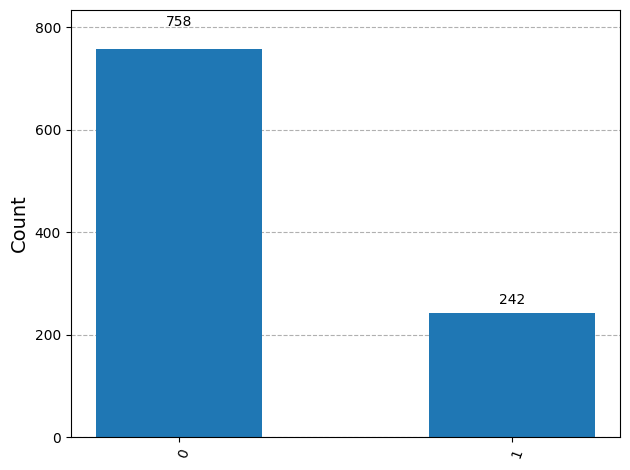

In [ ]:
plot_histogram(result)

In [ ]:

# Cirq: same idea
import cirq
import numpy as np

q = cirq.LineQubit(0)
theta = np.pi/3

circuit = cirq.Circuit(
    cirq.ry(theta).on(q),
    cirq.measure(q, key="m")
)
print(circuit)

sim = cirq.Simulator()
result = sim.run(circuit, repetitions=200)
print("Cirq histogram:", result.histogram(key="m"))


0: ───Ry(0.333π)───M('m')───
Cirq histogram: Counter({0: 159, 1: 41})



## Two-qubit gates: CNOT and controlled operations
Next notebook builds Bell states.
